In [89]:
import numpy as N
import pandas as P
import matplotlib.pyplot as MP
import statsmodels.stats.weightstats as SSW
import scipy.stats as S

In [65]:
df = P.read_csv('habits.data', sep= ';')

In [66]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 780 entries, 0 to 779
Data columns (total 11 columns):
 #   Column  Non-Null Count  Dtype  
---  ------  --------------  -----  
 0   kohde   780 non-null    int64  
 1   jasen   780 non-null    int64  
 2   pvknro  780 non-null    int64  
 3   sp      780 non-null    int64  
 4   ASALUE  780 non-null    float64
 5   IKAL1   780 non-null    int64  
 6   A1      780 non-null    str    
 7   A2      780 non-null    str    
 8   A3      780 non-null    str    
 9   A4      780 non-null    str    
 10  A5      780 non-null    str    
dtypes: float64(1), int64(5), str(5)
memory usage: 67.2 KB


In [67]:
# make categorical variables categorical and make their values human-readable
#df.kohde = P.Categorical(df.kohde)

#turn into string
df.kohde = df.kohde.astype('string')

df.jasen = P.Categorical(df.jasen)


df.pvknro = P.Categorical(df.pvknro).rename_categories({1: 'Working day',2: 'Weekend',})
df.sp = P.Categorical(df.sp).rename_categories({1: 'Male',2: 'Female',})
df.ASALUE = P.Categorical(df.ASALUE).rename_categories({1: 'city',2: 'municipality', 3:'rural area'})


In [68]:
df.IKAL1 = P.Categorical(df.IKAL1, ordered=True)


In [69]:
# Check that ordered
df.IKAL1.cat.ordered

True

In [70]:
#Check for incorrect values
df.IKAL1.unique()

[6, 7, 4, 8, 3, 9, 5]
Categories (7, int64): [3 < 4 < 5 < 6 < 7 < 8 < 9]

In [71]:
#converts hour:minute strings into minutes integer. ? into nan
def clean(s:str):
    if ':' in s:
        split = s.split(sep=':')
        hours = float(split[0])
        minutes = float(split[1])
        total_minutes = 60*hours + minutes 
        return total_minutes
    elif '?' in s:
        return N.nan
    else: return float(s)    

In [72]:
#clean columns A1, A2, A3 from hours:minute and ? strings.
df[['A1', 'A2', 'A3']]= df[['A1', 'A2', 'A3']].map(clean)

In [73]:
df[['A1', 'A2', 'A3']].astype('float64')

,A1,A2,A3
0,190.0,450.0,13.0
1,235.0,480.0,52.0
2,175.0,460.0,104.0
3,180.0,460.0,0.0
4,0.0,600.0,10.0
...,...,...,...
775,230.0,450.0,39.0
776,0.0,790.0,0.0
777,0.0,730.0,0.0
778,0.0,490.0,52.0


In [74]:
def clean(s:str):
    if s in ['1.0', '2.0', '?']:
        return s
    else: return '1.0'    

In [75]:
#clean columns A4, A5, Convert hours:minutes strings to 1.0.
df[['A4', 'A5']]= df[['A4', 'A5']].map(clean)

In [76]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 780 entries, 0 to 779
Data columns (total 11 columns):
 #   Column  Non-Null Count  Dtype   
---  ------  --------------  -----   
 0   kohde   780 non-null    string  
 1   jasen   780 non-null    category
 2   pvknro  780 non-null    category
 3   sp      780 non-null    category
 4   ASALUE  780 non-null    category
 5   IKAL1   780 non-null    category
 6   A1      773 non-null    float64 
 7   A2      770 non-null    float64 
 8   A3      776 non-null    float64 
 9   A4      780 non-null    str     
 10  A5      780 non-null    str     
dtypes: category(5), float64(3), str(2), string(1)
memory usage: 40.7 KB


In [77]:
df.A4 = P.Categorical(df.A4).rename_categories({'1.0': 'Yes','2.0': 'No', '?' : 'Missing'})

In [78]:
df.A5 = P.Categorical(df.A5).rename_categories({'1.0': 'Yes','2.0': 'No', '?' : 'Missing'})

In [79]:
df = df.rename(columns={'A1' : 'working',
'A2' : 'sleeping',
'A3' : 'reading',
'A4' : 'restaurant',
'A5' : 'visiting library'})

In [80]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 780 entries, 0 to 779
Data columns (total 11 columns):
 #   Column            Non-Null Count  Dtype   
---  ------            --------------  -----   
 0   kohde             780 non-null    string  
 1   jasen             780 non-null    category
 2   pvknro            780 non-null    category
 3   sp                780 non-null    category
 4   ASALUE            780 non-null    category
 5   IKAL1             780 non-null    category
 6   working           773 non-null    float64 
 7   sleeping          770 non-null    float64 
 8   reading           776 non-null    float64 
 9   restaurant        780 non-null    category
 10  visiting library  780 non-null    category
dtypes: category(7), float64(3), string(1)
memory usage: 30.1 KB


In [81]:
df.describe()

,working,sleeping,reading
count,773.000000,770.000000,776.000000
mean,78.693402,529.246753,56.944588
std,160.897259,103.946590,75.552013
min,0.000000,120.000000,0.000000
25%,0.000000,470.000000,0.000000
50%,0.000000,530.000000,30.000000
75%,20.000000,590.000000,80.000000
max,910.000000,1050.000000,572.000000


Looks ok

In [82]:
categorical = ['kohde', 'jasen', 'pvknro', 'sp', 'ASALUE', 'IKAL1', 'restaurant', 'visiting library' ]
# explore categorical variables

for col in categorical:
    print(col, end="\n\n")
    print(df[col].value_counts().sort_index(), end="\n\n")


kohde

kohde
50002    2
50009    1
50011    1
50012    1
50015    2
        ..
51977    2
51978    2
51980    1
51981    2
51982    2
Name: count, Length: 494, dtype: Int64

jasen

jasen
1    465
2    315
Name: count, dtype: int64

pvknro

pvknro
Working day    418
Weekend        362
Name: count, dtype: int64

sp

sp
Male      374
Female    406
Name: count, dtype: int64

ASALUE

ASALUE
city            519
municipality    124
rural area      137
Name: count, dtype: int64

IKAL1

IKAL1
3     34
4    106
5    132
6    170
7    165
8    112
9     61
Name: count, dtype: int64

restaurant

restaurant
Yes        383
No         357
Missing     40
Name: count, dtype: int64

visiting library

visiting library
Yes        509
No         233
Missing     38
Name: count, dtype: int64



,working,sleeping,reading
count,773.000000,770.000000,776.000000
mean,78.693402,529.246753,56.944588
std,160.897259,103.946590,75.552013
min,0.000000,120.000000,0.000000
25%,0.000000,470.000000,0.000000
50%,0.000000,530.000000,30.000000
75%,20.000000,590.000000,80.000000
max,910.000000,1050.000000,572.000000


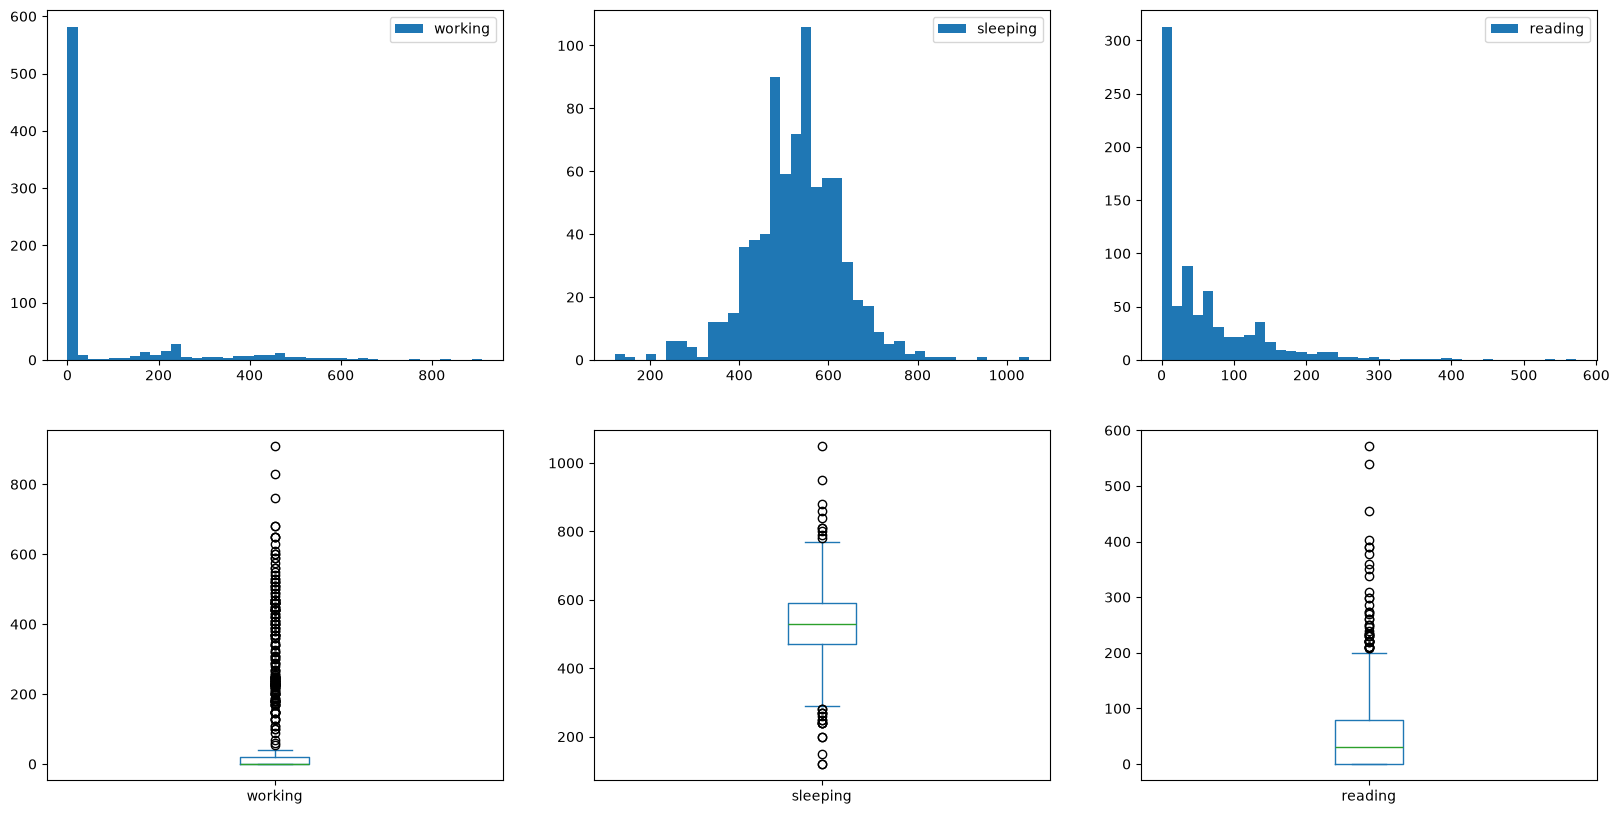

In [83]:
quantitative = ['working', 'sleeping', 'reading']
# explore quantitative variables

fig, axes = MP.subplots(nrows=2, ncols=3, figsize=(20, 10))
for i, col in enumerate(quantitative):
    df[col].hist(bins=40, ax=axes[0, i], legend=True)
    axes[0, i].grid(False)
    df.plot.box(column=col, ax=axes[1, i])

df[quantitative].describe()


Doctors etc work long hours occasionally and somepeople might spend 10 hours a day reading, but the 2 largest observations in the sleeping box plot are probably incorrect and should be discarded.

In [ ]:
#Change too largest values in sleeping column to NaN
df.iloc[df.sleeping.idxmax(), 7] = N.nan
df.iloc[df.sleeping.idxmax(), 7] = N.nan

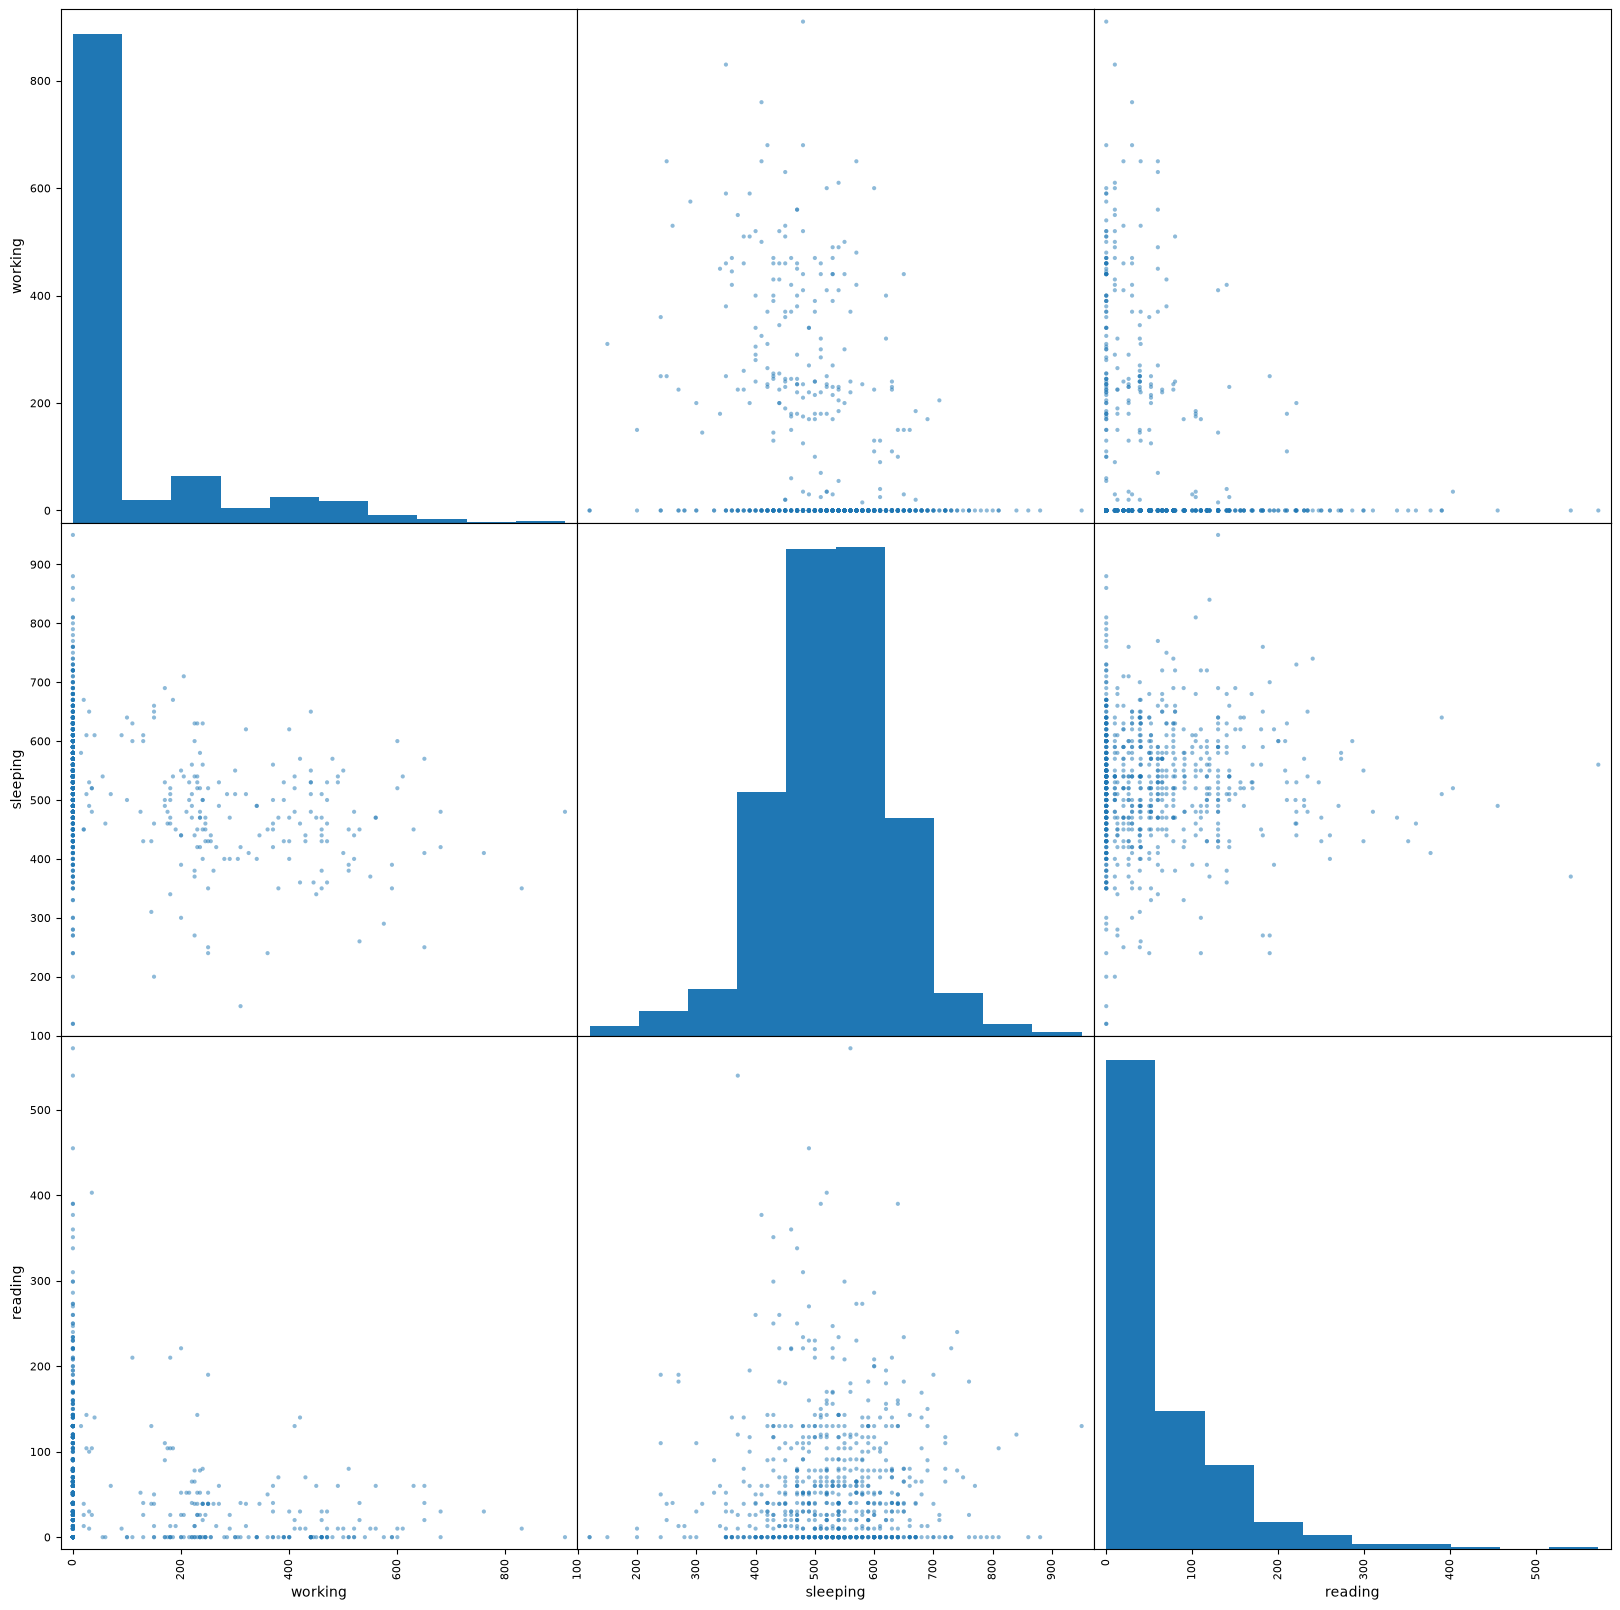

In [85]:
# explore pair-wise relationships

dontprint = P.plotting.scatter_matrix(df[quantitative], figsize=(20,20))

In [86]:
df[['working','sleeping','reading'
]].aggregate(['mean', 'var','std']).round(2)

,working,sleeping,reading
mean,78.69,528.57,56.94
var,25887.93,10465.40,5708.11
std,160.90,102.30,75.55


In [87]:
df.groupby(['sp'])[['working', 'sleeping', 'reading']].mean()

,working,sleeping,reading
sp,,,
Male,91.693767,530.380435,52.702413
Female,66.819307,526.907731,60.870968


The differences in the mean number of hours spent working a day differs significantly between men and women. The means for the number of hours spent sleeping and reading do not seem to differ much. Let's investigate whether these differences are statistically significant. In order to select the proper statistical test, the male and female subpopulations' working hour data will should be tested for normality:

In [98]:
print(S.shapiro(df[df['sp'] == 'Male']['working'].dropna()).pvalue)
print(S.shapiro(df[df['sp'] == 'Female']['working'].dropna()).pvalue)
print(S.shapiro(df[df['sp'] == 'Male']['sleeping'].dropna()).pvalue)
print(S.shapiro(df[df['sp'] == 'Female']['sleeping'].dropna()).pvalue)
print(S.shapiro(df[df['sp'] == 'Male']['reading'].dropna()).pvalue)
print(S.shapiro(df[df['sp'] == 'Female']['reading'].dropna()).pvalue)

2.010927593341736e-28
1.992700048102293e-31
0.0029986987639865656
1.1455081795940225e-06
1.3614730984624634e-24
2.0485123035879092e-23


The p-values are all small, so the data cannot be assumed to be normally distributed.

In [88]:
df.groupby(['sp'])[['restaurant', 'visiting library']].

SyntaxError: invalid syntax (3214551739.py, line 1)